C:\Users\Ashil-Rayan\AppData\Local\Temp\ipykernel_3408\3818711078.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  gnuplot = cm.get_cmap('gnuplot', n)


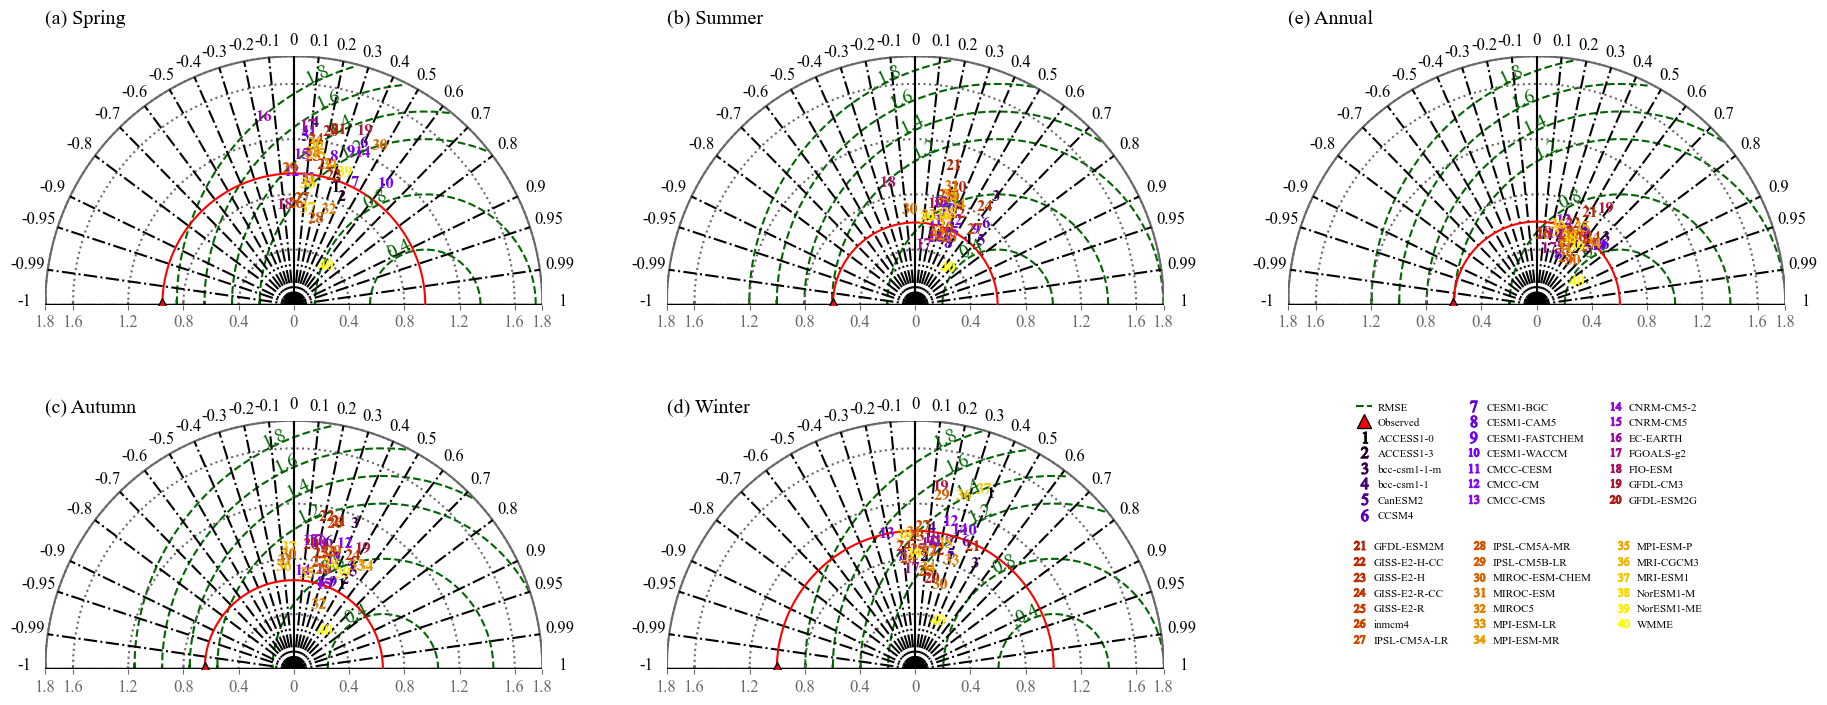

In [10]:
import argparse
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import skill_metrics as sm
import numpy as np
import colorsys
from matplotlib.colors import to_hex
import pandas as pd
import matplotlib.cm as cm

# تنظیم فونت Times New Roman برای همه عناصر نمودار
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

# DATA #################################################################
LEGEND_SUBPLOT = (1, 2)

# مسیر فایل‌های اکسل
EXCEL_PATHS = {
    'Annual': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP5\\YM.xlsx',
    'Winter': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP5\\DJF.xlsx',
    'Spring': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP5\\MAM.xlsx',
    'Summer': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP5\\JJA.xlsx',
    'Autumn': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP5\\SON.xlsx'
}

# خواندن داده‌ها از اکسل و ایجاد لیست مدل‌ها
def read_excel_data(filepath):
    df = pd.read_excel(filepath, sheet_name=0)
    models = df['File'].tolist()
    data = {
        'SD_Model': df['SD_Model'].tolist(),
        'RMSE': df['RMSE'].tolist(),
        'Correlation': df['Correlation'].tolist(),
        'SD_Obs': df['SD_Obs'].iloc[0]  # مقدار مشاهدات برای همه یکسان است
    }
    return models, data

# خواندن داده‌ها برای تمام فصول
all_data = {}
for season, path in EXCEL_PATHS.items():
    models, season_data = read_excel_data(path)
    all_data[season] = {'models': models, 'data': season_data}

# ایجاد لیست مدل‌ها از داده‌های خوانده شده
MODELS = all_data['Annual']['models']
NUM_MODELS = len(MODELS)

# تابع تولید رنگ‌های متمایز
def generate_distinct_colors(n):
    gnuplot = cm.get_cmap('gnuplot', n)
    return [to_hex(gnuplot(i)) for i in range(n)]

# تولید رنگ‌های منحصر به فرد برای مدل‌ها
model_colors = generate_distinct_colors(NUM_MODELS)

# ساختار داده‌های نمودار
SUBPLOTS_DATA = [
    {
        "axis_idx": (0, 0),
        "title": "(a) Spring",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Spring']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Spring']['models'],
            zip(
                all_data['Spring']['data']['SD_Model'],
                all_data['Spring']['data']['RMSE'],
                all_data['Spring']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (0, 1),
        "title": "(b) Summer",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Summer']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Summer']['models'],
            zip(
                all_data['Summer']['data']['SD_Model'],
                all_data['Summer']['data']['RMSE'],
                all_data['Summer']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (0, 2),
        "title": "(e) Annual",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Annual']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Annual']['models'],
            zip(
                all_data['Annual']['data']['SD_Model'],
                all_data['Annual']['data']['RMSE'],
                all_data['Annual']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (1, 0),
        "title": "(c) Autumn",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Autumn']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Autumn']['models'],
            zip(
                all_data['Autumn']['data']['SD_Model'],
                all_data['Autumn']['data']['RMSE'],
                all_data['Autumn']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (1, 1),
        "title": "(d) Winter",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Winter']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Winter']['models'],
            zip(
                all_data['Winter']['data']['SD_Model'],
                all_data['Winter']['data']['RMSE'],
                all_data['Winter']['data']['Correlation']
            )
        ))
    }
]

MARKERS = {
    "Observed": {
        "marker": "^",
        "color_edge": "#FF0000",
        "color_face": "#000000",
        "markersize": 10,
        "label": "Obsv"
    }
}

# اضافه کردن رنگ‌های تولید شده به مدل‌ها
for i, model in enumerate(MODELS):
    MARKERS[model] = {
        "number": str(i+1),
        "color": model_colors[i],
        "markersize": 10,
        "label": model
    }

# PLOT STYLE ###########################################################
FONT_SIZE = 12

COLS_COR = {
    'grid': 'black',
    'tick_labels': 'black',
    'title': 'black'
}

COLS_STD = {
    'grid': 'dimgray',
    'tick_labels': 'dimgray',
    'ticks': 'dimgray',
    'title': 'dimgray'
}

STYLES_RMS = {
    'color': 'darkgreen',
    'linestyle': '--'
}

# MAIN #################################################################
# تنظیم فونت در rcParams (قبلاً در بالای کد انجام شده)

fig, axs = plt.subplots(2, 3, figsize=(20, 8), sharey=True)

for subplot_data in SUBPLOTS_DATA:
    ax = axs[subplot_data["axis_idx"][0]][subplot_data["axis_idx"][1]]
    ax.set(adjustable='box', aspect='equal')

    # Plot observed data
    stdev, crmsd, ccoef = subplot_data["observed"]
    sm.taylor_diagram(ax,
                 np.asarray((stdev, stdev)), 
                 np.asarray((crmsd, crmsd)), 
                 np.asarray((ccoef, ccoef)),
                 markercolors={
                     "face": MARKERS["Observed"]["color_edge"],
                     "edge": MARKERS["Observed"]["color_face"]
                 },
                 markersize=MARKERS["Observed"]["markersize"],
                 markersymbol=MARKERS["Observed"]["marker"],
                 styleOBS='-',
                 colOBS=MARKERS["Observed"]["color_edge"],
                 alpha=0.9,
                 titleSTD='off',
                 titleRMS='off',
                 titleCOR='off',
                 showlabelsRMS='on',
                 tickRMS=[0.4, 0.8, 1.2, 1.4, 1.6, 1.8],
                 colRMS=STYLES_RMS['color'],
                 tickRMSangle=115,
                 styleRMS=STYLES_RMS['linestyle'],
                 colscor=COLS_COR,
                 colsstd=COLS_STD,
                 styleCOR='-.',
                 styleSTD=':',
                 colframe='#000000',
                 labelweight='normal',
                 titlecorshape='linear',
                 tickSTD=[0.4, 0.8, 1.2, 1.6, 1.8],
                 rmslabelformat=':.1f',
                 axismax=1.8)
    
    # Set titles and labels با فونت Times New Roman
    if subplot_data["axis_idx"] in [(1,0), (1,1)]:  # برای پاییز و زمستان
        title_y = 1
    else:
        title_y = 1.1
        
    ax.set_title(subplot_data["title"], loc="left", y=title_y, fontfamily='Times New Roman')
    
    if subplot_data["y_label"]:
        ax.set_ylabel("Standard Deviation", fontsize=FONT_SIZE+2, fontfamily='Times New Roman')
    if not subplot_data["x_label"]:
        ax.set_xticklabels([])

    # Plot models with number markers (no circles)
    for model_id, (stdev, crmsd, ccoef) in subplot_data["modeled"].items():
        marker = MARKERS[model_id]
        
        # Convert polar to cartesian coordinates
        theta = np.arccos(ccoef)
        x = stdev * np.cos(theta)
        y = stdev * np.sin(theta)
        
        # Add number as text without circle background با فونت Times New Roman
        ax.text(x, y, marker["number"],
                ha='center', va='center',
                color=marker["color"],
                fontsize=12,
                fontfamily='Times New Roman',
                fontweight='bold')

# Create legend in the last subplot
center_ax = axs[LEGEND_SUBPLOT[0]][LEGEND_SUBPLOT[1]]
center_ax.axis('off')

# Build legend handles
legend_handles = [
    mlines.Line2D([], [], color=STYLES_RMS['color'],
                 linestyle=STYLES_RMS['linestyle'], label="RMSE"),
    mlines.Line2D([], [], marker=MARKERS["Observed"]["marker"],
                 markersize=MARKERS["Observed"]["markersize"],
                 markerfacecolor=MARKERS["Observed"]["color_edge"],
                 markeredgecolor=MARKERS["Observed"]["color_face"],
                 linestyle='None', label="Observed")
]

# Add model markers to legend (as text only)
for model in MODELS:
    marker = MARKERS[model]
    legend_handles.append(
        mlines.Line2D([], [], marker='$'+marker["number"]+'$',
                     markersize=8,
                     color=marker["color"],
                     linestyle='None',
                     label=marker['label'])
    )

# تقسیم مدل‌ها به دو گروه
half = len(MODELS) // 2
legend_handles_group1 = legend_handles[:2] + [h for h in legend_handles[2:] if h.get_label() in MODELS[:half]]
legend_handles_group2 = [h for h in legend_handles[2:] if h.get_label() in MODELS[half:]]

# تنظیمات مشترک برای هر دو راهنما با فونت Times New Roman
legend_kwargs = {
    'frameon': True,
    'fancybox': True,
    'facecolor': 'white',
    'edgecolor': 'white',
    'fontsize': 8,
    'borderpad': 0.5,
    'labelspacing': 0.5,
    'handlelength': 1.5,
    'handletextpad': 0.5,
    'prop': {'family': 'Times New Roman', 'size': 8}  # اضافه کردن فونت به prop
}

# نمایش دو راهنمای جداگانه
legend1 = center_ax.legend(handles=legend_handles_group1, 
                         loc='upper center', 
                         bbox_to_anchor=(0.48, 1.03), 
                         ncol=3,
                         **legend_kwargs)

legend2 = center_ax.legend(handles=legend_handles_group2, 
                         loc='lower center', 
                         bbox_to_anchor=(0.48, 0.12), 
                         ncol=3,
                         **legend_kwargs)

# اضافه کردن دستی راهنماها به نمودار
center_ax.add_artist(legend1)

plt.subplots_adjust(
    left=0.08,
    right=0.95,
    bottom=0.08,
    top=0.90,
    wspace=0.25,
    hspace=0.25
)


# بهبود رزولوشن خروجی (با اضافه کردن bbox_extra_artists)
plt.savefig('C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP5\\taylor_diagram-CMIP5.png', 
           dpi=300, 
           bbox_extra_artists=[legend1, legend2],  # اضافه کردن راهنماها
           facecolor='white')

# نمایش نمودار
plt.show()


In [ ]:
import argparse
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import skill_metrics as sm
import numpy as np
import colorsys
from matplotlib.colors import to_hex
import pandas as pd
import matplotlib.cm as cm

# تنظیم فونت Times New Roman برای همه عناصر
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

# DATA #################################################################
LEGEND_SUBPLOT = (1, 2)

# مسیر فایل‌های اکسل
EXCEL_PATHS = {
    'Annual': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP6\\YM.xlsx',
    'Winter': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP6\\DJF.xlsx',
    'Spring': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP6\\MAM.xlsx',
    'Summer': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP6\\JJA.xlsx',
    'Autumn': 'C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP6\\SON.xlsx'
}

# خواندن داده‌ها از اکسل و ایجاد لیست مدل‌ها
def read_excel_data(filepath):
    df = pd.read_excel(filepath, sheet_name=0)
    models = df['File'].tolist()
    data = {
        'SD_Model': df['SD_Model'].tolist(),
        'RMSE': df['RMSE'].tolist(),
        'Correlation': df['Correlation'].tolist(),
        'SD_Obs': df['SD_Obs'].iloc[0]  # مقدار مشاهدات برای همه یکسان است
    }
    return models, data

# خواندن داده‌ها برای تمام فصول
all_data = {}
for season, path in EXCEL_PATHS.items():
    models, season_data = read_excel_data(path)
    all_data[season] = {'models': models, 'data': season_data}

# ایجاد لیست مدل‌ها از داده‌های خوانده شده
MODELS = all_data['Annual']['models']
NUM_MODELS = len(MODELS)

# تابع تولید رنگ‌های متمایز
def generate_distinct_colors(n):
    gnuplot = cm.get_cmap('gnuplot', n)
    return [to_hex(gnuplot(i)) for i in range(n)]

# تولید رنگ‌های منحصر به فرد برای مدل‌ها
model_colors = generate_distinct_colors(NUM_MODELS)

# ساختار داده‌های نمودار
SUBPLOTS_DATA = [
    {
        "axis_idx": (0, 0),
        "title": "(a) Spring",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Spring']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Spring']['models'],
            zip(
                all_data['Spring']['data']['SD_Model'],
                all_data['Spring']['data']['RMSE'],
                all_data['Spring']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (0, 1),
        "title": "(b) Summer",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Summer']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Summer']['models'],
            zip(
                all_data['Summer']['data']['SD_Model'],
                all_data['Summer']['data']['RMSE'],
                all_data['Summer']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (0, 2),
        "title": "(e) Annual",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Annual']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Annual']['models'],
            zip(
                all_data['Annual']['data']['SD_Model'],
                all_data['Annual']['data']['RMSE'],
                all_data['Annual']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (1, 0),
        "title": "(c) Autumn",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Autumn']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Autumn']['models'],
            zip(
                all_data['Autumn']['data']['SD_Model'],
                all_data['Autumn']['data']['RMSE'],
                all_data['Autumn']['data']['Correlation']
            )
        ))
    },
    {
        "axis_idx": (1, 1),
        "title": "(d) Winter",
        "y_label": True,
        "x_label": True,
        "observed": (all_data['Winter']['data']['SD_Obs'], 0.00, -1.00),
        "modeled": dict(zip(
            all_data['Winter']['models'],
            zip(
                all_data['Winter']['data']['SD_Model'],
                all_data['Winter']['data']['RMSE'],
                all_data['Winter']['data']['Correlation']
            )
        ))
    }
]

MARKERS = {
    "Observed": {
        "marker": "^",
        "color_edge": "#FF0000",
        "color_face": "#000000",
        "markersize": 10,
        "label": "Obsv"
    }
}

# اضافه کردن رنگ‌های تولید شده به مدل‌ها
for i, model in enumerate(MODELS):
    MARKERS[model] = {
        "number": str(i+1),
        "color": model_colors[i],
        "markersize": 10,
        "label": model
    }

# PLOT STYLE ###########################################################
FONT_SIZE = 12

COLS_COR = {
    'grid': 'black',
    'tick_labels': 'black',
    'title': 'black'
}

COLS_STD = {
    'grid': 'dimgray',
    'tick_labels': 'dimgray',
    'ticks': 'dimgray',
    'title': 'dimgray'
}

STYLES_RMS = {
    'color': 'darkgreen',
    'linestyle': '--'
}

# MAIN #################################################################
# تنظیم فونت در rcParams (قبلاً در بالای کد انجام شده)

fig, axs = plt.subplots(2, 3, figsize=(20, 8), sharey=True)

for subplot_data in SUBPLOTS_DATA:
    ax = axs[subplot_data["axis_idx"][0]][subplot_data["axis_idx"][1]]
    ax.set(adjustable='box', aspect='equal')

    # Plot observed data
    stdev, crmsd, ccoef = subplot_data["observed"]
    sm.taylor_diagram(ax,
                 np.asarray((stdev, stdev)), 
                 np.asarray((crmsd, crmsd)), 
                 np.asarray((ccoef, ccoef)),
                 markercolors={
                     "face": MARKERS["Observed"]["color_edge"],
                     "edge": MARKERS["Observed"]["color_face"]
                 },
                 markersize=MARKERS["Observed"]["markersize"],
                 markersymbol=MARKERS["Observed"]["marker"],
                 styleOBS='-',
                 colOBS=MARKERS["Observed"]["color_edge"],
                 alpha=0.9,
                 titleSTD='off',
                 titleRMS='off',
                 titleCOR='off',
                 showlabelsRMS='on',
                 tickRMS=[0.4, 0.8, 1.2, 1.4, 1.6, 1.8],
                 colRMS=STYLES_RMS['color'],
                 tickRMSangle=115,
                 styleRMS=STYLES_RMS['linestyle'],
                 colscor=COLS_COR,
                 colsstd=COLS_STD,
                 styleCOR='-.',
                 styleSTD=':',
                 colframe='#000000',
                 labelweight='normal',
                 titlecorshape='linear',
                 tickSTD=[0.4, 0.8, 1.2, 1.6, 1.8],
                 rmslabelformat=':.1f',
                 axismax=1.8)
    
    # Set titles and labels با فونت Times New Roman
    if subplot_data["axis_idx"] in [(1,0), (1,1)]:  # برای پاییز و زمستان
        title_y = 1
    else:
        title_y = 1.1
        
    ax.set_title(subplot_data["title"], loc="left", y=title_y, fontfamily='Times New Roman')
    
    if subplot_data["y_label"]:
        ax.set_ylabel("Standard Deviation", fontsize=FONT_SIZE+2, fontfamily='Times New Roman')
    if not subplot_data["x_label"]:
        ax.set_xticklabels([])

    # Plot models with number markers (no circles)
    for model_id, (stdev, crmsd, ccoef) in subplot_data["modeled"].items():
        marker = MARKERS[model_id]
        
        # Convert polar to cartesian coordinates
        theta = np.arccos(ccoef)
        x = stdev * np.cos(theta)
        y = stdev * np.sin(theta)
        
        # Add number as text without circle background با فونت Times New Roman
        ax.text(x, y, marker["number"],
                ha='center', va='center',
                color=marker["color"],
                fontsize=12,
                fontfamily='Times New Roman',
                fontweight='bold')

# Create legend in the last subplot
center_ax = axs[LEGEND_SUBPLOT[0]][LEGEND_SUBPLOT[1]]
center_ax.axis('off')

# Build legend handles
legend_handles = [
    mlines.Line2D([], [], color=STYLES_RMS['color'],
                 linestyle=STYLES_RMS['linestyle'], label="RMSE"),
    mlines.Line2D([], [], marker=MARKERS["Observed"]["marker"],
                 markersize=MARKERS["Observed"]["markersize"],
                 markerfacecolor=MARKERS["Observed"]["color_edge"],
                 markeredgecolor=MARKERS["Observed"]["color_face"],
                 linestyle='None', label="Observed")
]

# Add model markers to legend (as text only)
for model in MODELS:
    marker = MARKERS[model]
    legend_handles.append(
        mlines.Line2D([], [], marker='$'+marker["number"]+'$',
                     markersize=8,
                     color=marker["color"],
                     linestyle='None',
                     label=marker['label'])
    )

# تقسیم مدل‌ها به دو گروه
half = len(MODELS) // 2
legend_handles_group1 = legend_handles[:2] + [h for h in legend_handles[2:] if h.get_label() in MODELS[:half]]
legend_handles_group2 = [h for h in legend_handles[2:] if h.get_label() in MODELS[half:]]

# تنظیمات مشترک برای هر دو راهنما با فونت Times New Roman
legend_kwargs = {
    'frameon': True,
    'fancybox': True,
    'facecolor': 'white',
    'edgecolor': 'white',
    'fontsize': 8,
    'borderpad': 0.5,
    'labelspacing': 0.5,
    'handlelength': 1.5,
    'handletextpad': 0.5,
    'prop': {'family': 'Times New Roman', 'size': 8}
}

# نمایش دو راهنمای جداگانه
legend1 = center_ax.legend(handles=legend_handles_group1, 
                         loc='upper center', 
                         bbox_to_anchor=(0.48, 1.05), 
                         ncol=3,
                         **legend_kwargs)

legend2 = center_ax.legend(handles=legend_handles_group2, 
                         loc='lower center', 
                         bbox_to_anchor=(0.48, 0.12), 
                         ncol=3,
                         **legend_kwargs)

# اضافه کردن دستی راهنماها به نمودار
center_ax.add_artist(legend1)

plt.subplots_adjust(
    left=0.08,
    right=0.95,
    bottom=0.08,
    top=0.90,
    wspace=0.25,
    hspace=0.25
)

# بهبود رزولوشن خروجی (با اضافه کردن bbox_extra_artists)
plt.savefig('C:\\Users\\Ashil-Rayan\\Downloads\\Result\\CMIP6\\taylor_diagram-CMIP6.png', 
           dpi=300, 
           bbox_extra_artists=[legend1, legend2],
           facecolor='white')

# نمایش نمودار
plt.show()

C:\Users\Ashil-Rayan\AppData\Local\Temp\ipykernel_3408\2949337870.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  gnuplot = cm.get_cmap('gnuplot', n)
